# WRMSSE M5 và hệ thống phân cấp

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


M5 tập hợp lưới sản phẩm × cửa hàng lên 12 cấp. Với mỗi chuỗi, scale là trung bình bình phương sai phân lịch sử sau lần bán khác 0 đầu tiên. RMSSE là căn bậc hai của MSE dự báo chia scale. Trọng số là tỷ trọng doanh thu lịch sử trong cấp chia 12. Contribution là trọng số nhân RMSSE và WRMSSE là tổng contribution.

Điểm trong cấp là 12 lần tổng contribution của cấp. Chuỗi trọng số 0 đóng góp 0. Evaluator dừng nếu scale không hữu hạn hoặc không dương ở chuỗi có trọng số dương. [Đặc tả và kiểm thử độc lập](../docs/WRMSSE_PREPARATION.md).

In [2]:
from src.wrmsse import LEVELS, M5_COUNTS, WRMSSEEvaluator
display(pd.DataFrame({"level": range(1, 13), "keys": LEVELS, "n_series": M5_COUNTS}))
audit = read(root / "preparation/data_context_audit.json")
display(pd.DataFrame([{k: v for k, v in item.items() if k.endswith("_days")} | {"fold": name} for name, item in audit["contexts"].items()]))

,level,keys,n_series
0,1,(),1
1,2,"(state_id,)",3
2,3,"(store_id,)",10
3,4,"(cat_id,)",3
4,5,"(dept_id,)",7
5,6,"(state_id, cat_id)",9
6,7,"(state_id, dept_id)",21
7,8,"(store_id, cat_id)",30
8,9,"(store_id, dept_id)",70
9,10,"(item_id,)",3049


,history_days,weight_days,forecast_days,fold
0,"[1, 1885]","[1858, 1885]","[1886, 1913]",validation
1,"[1, 1913]","[1886, 1913]","[1914, 1941]",test


,level,hierarchy,n_series,weight,rf_wrmsse_within_level,rf_contribution,sn_wrmsse_within_level,sn_contribution,wrmsse_improvement_pct
0,1,Toàn hệ thống,1,0.083333,0.561465,0.046789,0.751430,0.062619,25.280431
1,2,Bang,3,0.083333,0.580430,0.048369,0.754396,0.062866,23.060234
2,3,Cửa hàng,10,0.083333,0.652730,0.054394,0.799304,0.066609,18.337642
3,4,Ngành hàng,3,0.083333,0.601073,0.050089,0.762047,0.063504,21.123849
4,5,Bộ phận,7,0.083333,0.657674,0.054806,0.817086,0.068090,19.509856
5,6,Bang × ngành hàng,9,0.083333,0.635997,0.053000,0.782983,0.065249,18.772496
6,7,Bang × bộ phận,21,0.083333,0.684688,0.057057,0.830436,0.069203,17.550753
7,8,Cửa hàng × ngành hàng,30,0.083333,0.701347,0.058446,0.839263,0.069939,16.432937
8,9,Cửa hàng × bộ phận,70,0.083333,0.750878,0.062573,0.891855,0.074321,15.807211
9,10,Sản phẩm,3049,0.083333,0.887196,0.073933,1.032248,0.086021,14.052071


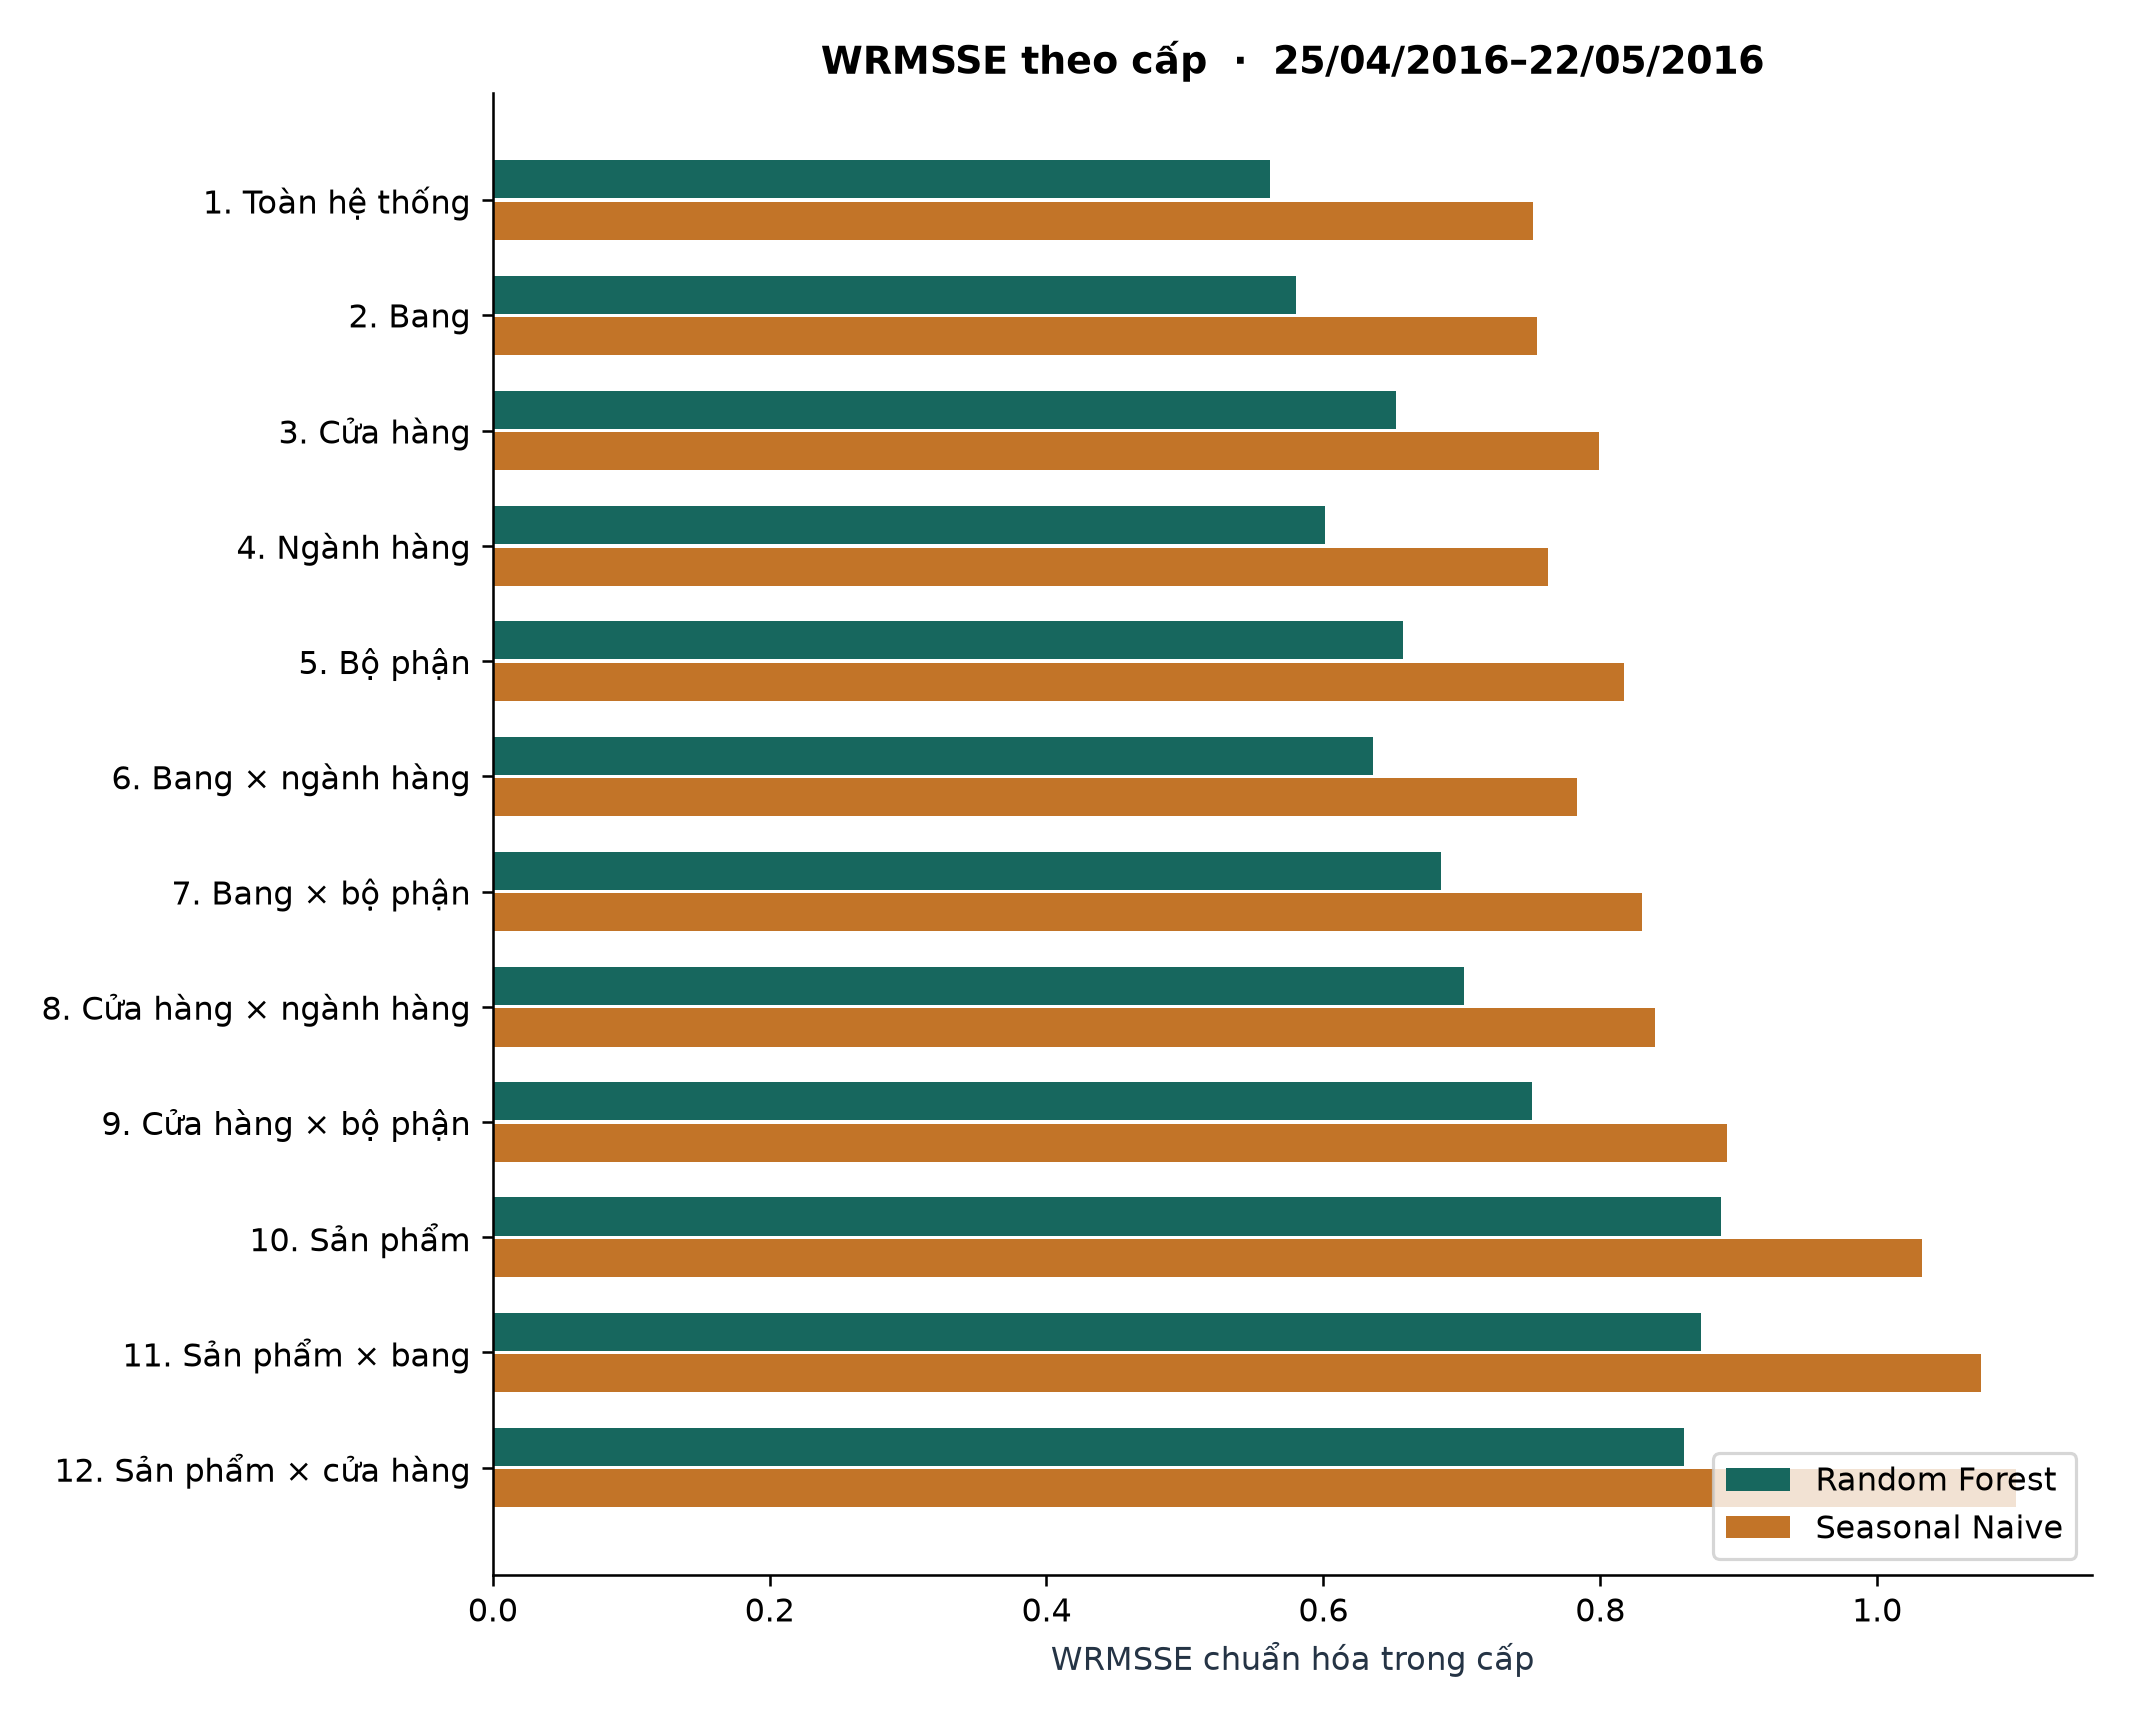

In [3]:
levels = table("wrmsse_12_levels")
display(levels)
assert abs(levels.weight.sum() - 1) < 1e-12
figure(11)